[Ссылка на репозиторий с имплементацией DeepGaze](https://github.com/matthias-k/DeepGaze)

[Ссылка на репозиторий с имплементацией UNISAL](https://github.com/rdroste/unisal)

In [7]:
%pip install -qq numpy scipy pillow matplotlib einops tensorboardX
%pip install -qq torch torchvision
%pip install -qq git+https://github.com/openai/CLIP.git
%pip install -qq git+https://github.com/matthias-k/DeepGaze.git

import os
import subprocess
if not os.path.exists('unisal'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/rdroste/unisal.git'])

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [8]:
import sys
import json
import time
from pathlib import Path
import urllib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import zoom
from scipy.special import logsumexp

import torch
from torchvision import transforms as T

sys.path.insert(0, os.path.abspath('unisal'))
import deepgaze_pytorch
from unisal.model import UNISAL

In [9]:
%config Inline.Backend.figure_format = "retina"
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

In [10]:
cb_file = "centerbias_mit1003.npy"
if not os.path.exists(cb_file):
    urllib.request.urlretrieve("https://github.com/matthias-k/DeepGaze/releases/download/v1.0.0/centerbias_mit1003.npy", cb_file)
centerbias_template = np.load(cb_file)

def prepare_centerbias(img_shape, template):
    h, w = img_shape[:2]
    cb = zoom(template, (h / template.shape[0], w / template.shape[1]), order=0, mode='nearest')
    cb -= logsumexp(cb)
    return torch.from_numpy(cb).unsqueeze(0).float().to(DEVICE)

In [11]:
model_msdb = deepgaze_pytorch.DeepGazeMSDB(pretrained=True).to(DEVICE).eval()
model_iie = deepgaze_pytorch.DeepGazeIIE(pretrained=True).to(DEVICE).eval()

with open('unisal/training_runs/pretrained_unisal/UNISAL.json') as f:
    cfg = json.load(f)
model_unisal = UNISAL(**cfg)
model_unisal.load_weights(Path('unisal/training_runs/pretrained_unisal'), 'best')
model_unisal.to(DEVICE).eval()

dummy_dg_img = torch.zeros((1, 3, 224, 384), dtype=torch.float32).to(DEVICE)
dummy_dg_cb = torch.zeros((1, 224, 384), dtype=torch.float32).to(DEVICE)
with torch.no_grad():
    _ = model_msdb(dummy_dg_img, dummy_dg_cb, pixel_per_dva=35.0, dataset=None)
    _ = model_iie(dummy_dg_img, dummy_dg_cb)

dummy_unisal = torch.zeros((1, 1, 3, 224, 384), dtype=torch.float32).to(DEVICE)
with torch.no_grad():
    _ = model_unisal(dummy_unisal, source='SALICON')

c:\Users\Misha_Savinov\Desktop\saliency-prediction\sp-venv\Lib\site-packages\torch\jit\_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(
Using cache found in C:\Users\Misha_Savinov/.cache\torch\hub\facebookresearch_dinov2_6a62615
C:\Users\Misha_Savinov/.cache\torch\hub\facebookresearch_dinov2_6a62615\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\Misha_Savinov/.cache\torch\hub\facebookresearch_dinov2_6a62615\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\Misha_Savinov/.cache\torch\hub\facebookresearch_dinov2_6a62615\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
c:\Users\Misha_Savinov\Desktop\saliency-prediction\

Loaded pretrained weights for efficientnet-b5


Using cache found in C:\Users\Misha_Savinov/.cache\torch\hub\pytorch_vision_v0.6.0
c:\Users\Misha_Savinov\Desktop\saliency-prediction\sp-venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet201_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet201_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Using cache found in C:\Users\Misha_Savinov/.cache\torch\hub\pytorch_vision_v0.6.0
c:\Users\Misha_Savinov\Desktop\saliency-prediction\sp-venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNeXt50_32X4D_Weights.IMAGENET1K_V1`. You can also use `weights=ResNeXt50_32X4D_Weights.

alenyshka.jpg (1280x770)
DeepGaze MSDB orig: 63.620s, resize: 57.092s
DeepGaze IIE orig: 4.113s, resize: 0.655s
UNISAL orig: 0.925s, resize: 0.076s



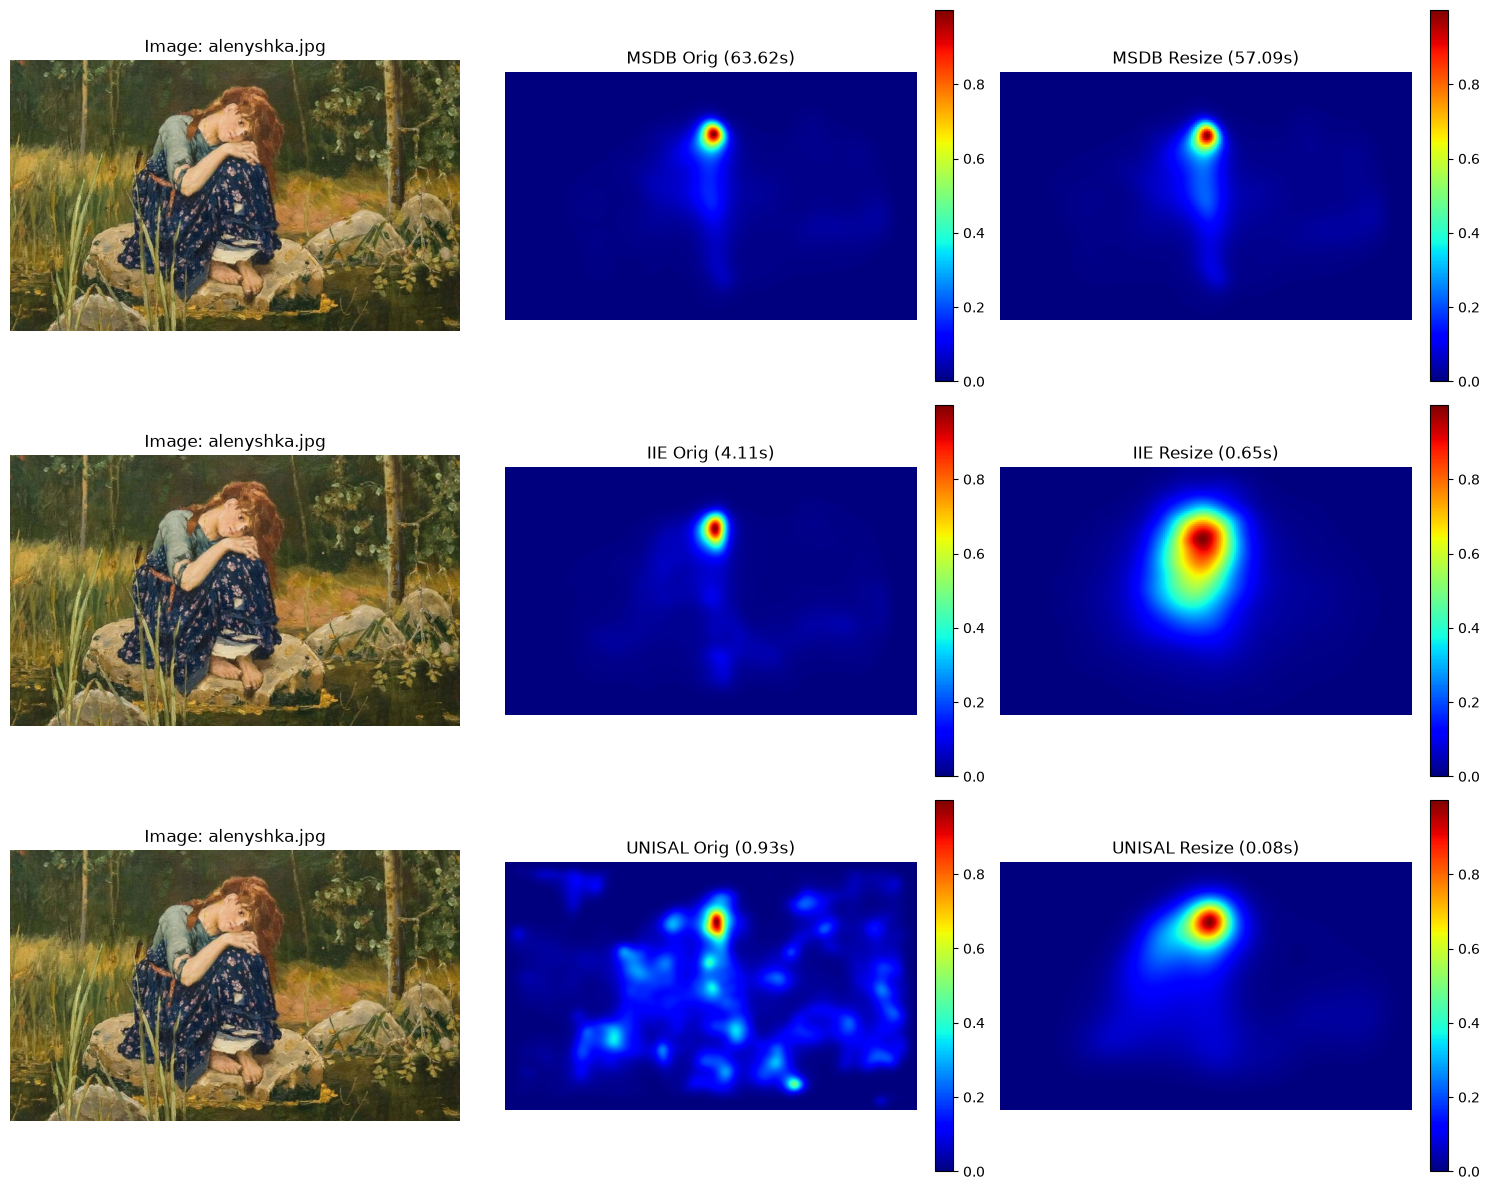

br_joi.jpg (1500x999)
DeepGaze MSDB orig: 92.114s, resize: 78.914s
DeepGaze IIE orig: 6.557s, resize: 0.653s
UNISAL orig: 1.162s, resize: 0.063s



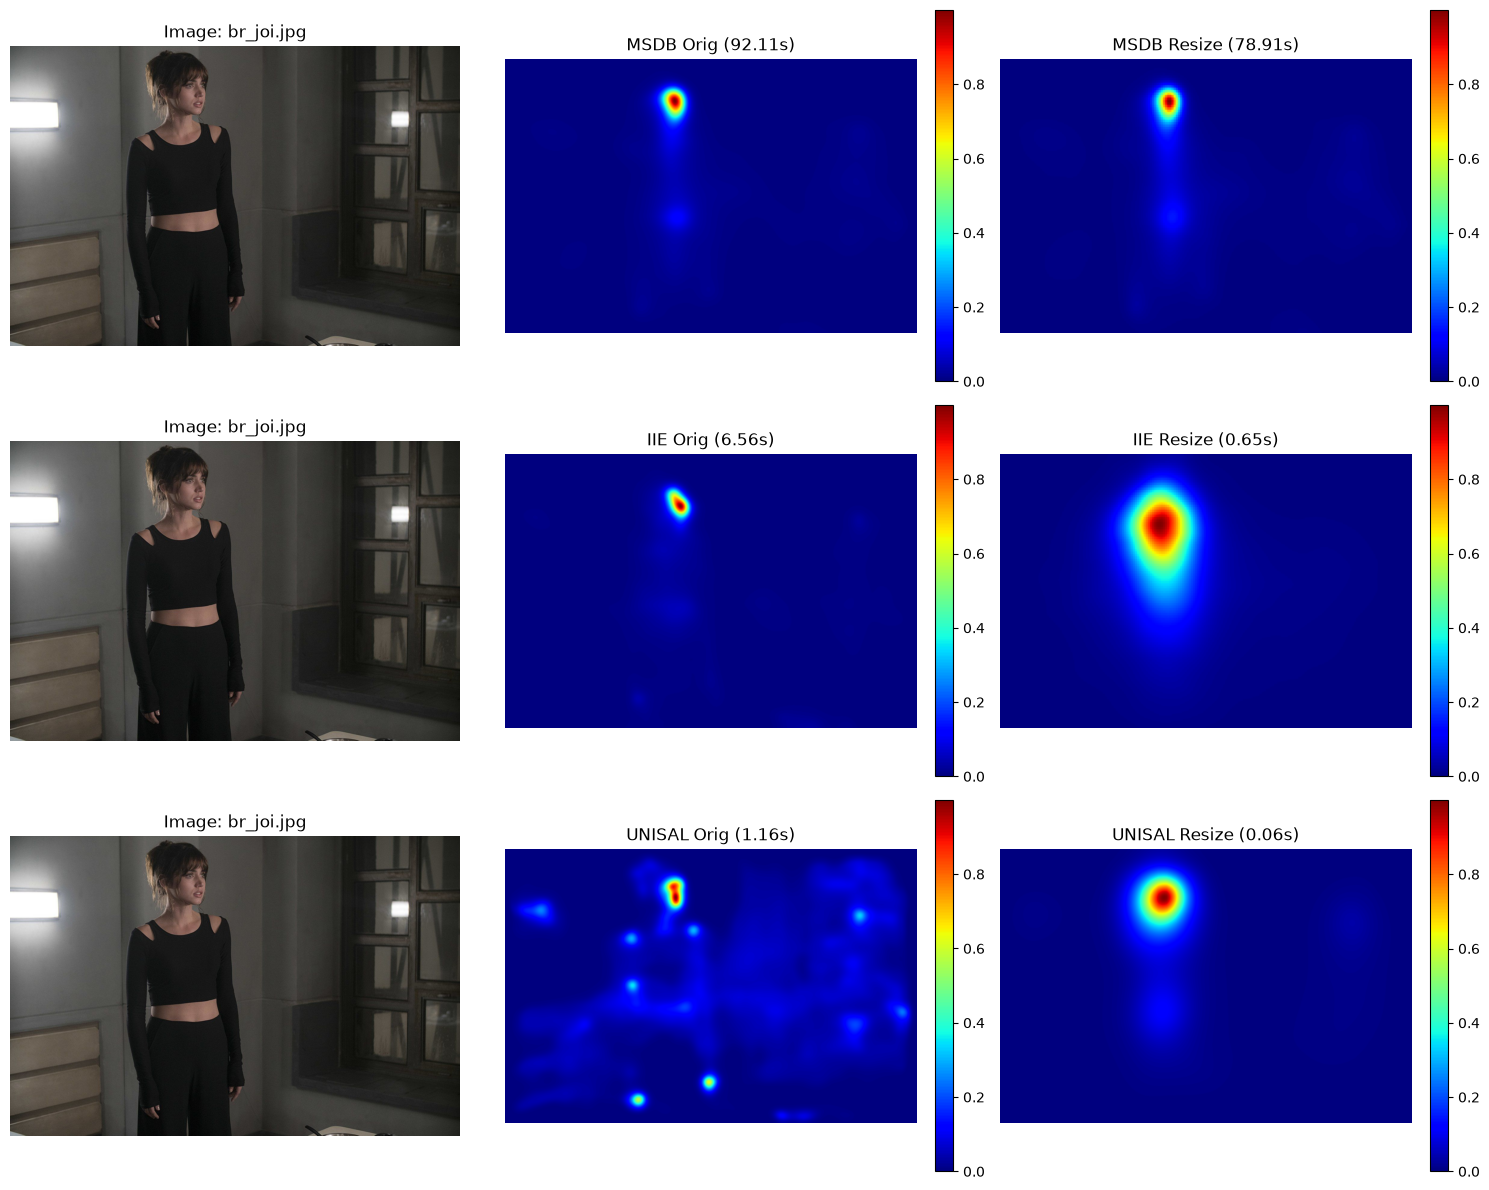

landscape.jpg (740x415)
DeepGaze MSDB orig: 32.866s, resize: 33.503s
DeepGaze IIE orig: 1.572s, resize: 0.687s
UNISAL orig: 0.228s, resize: 0.072s



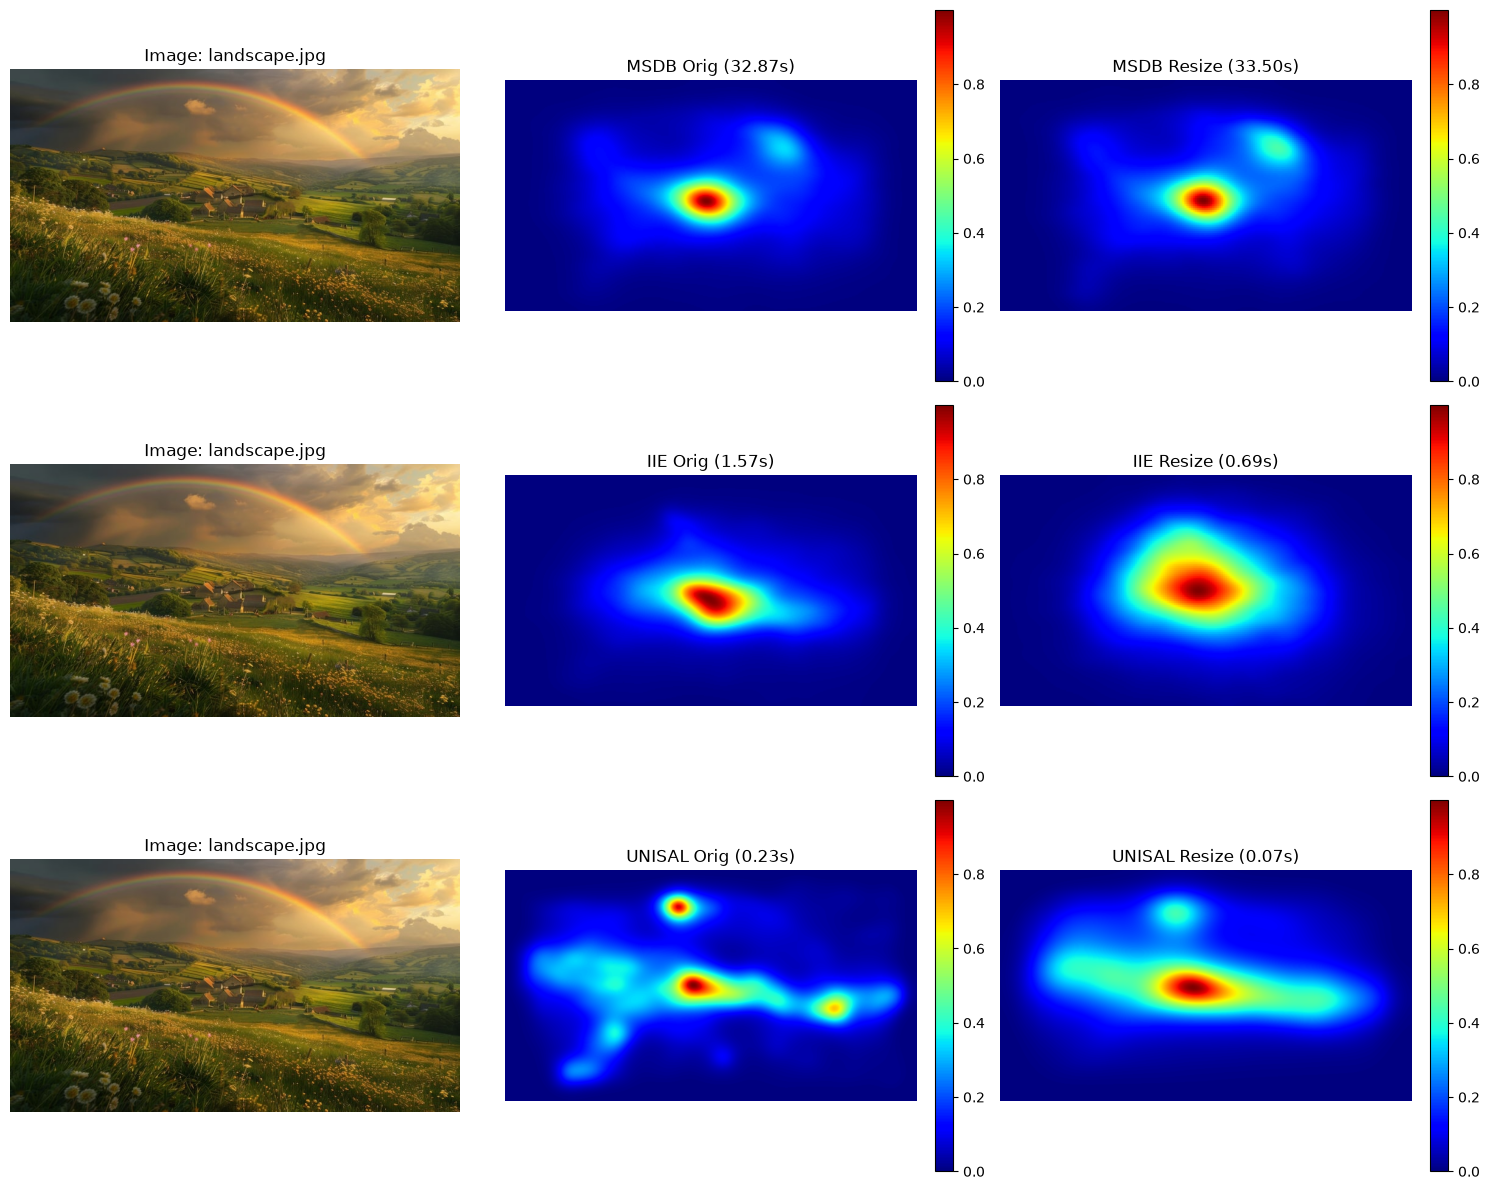

photo_flower.jpg (736x913)
DeepGaze MSDB orig: 59.839s, resize: 34.019s
DeepGaze IIE orig: 2.694s, resize: 0.673s
UNISAL orig: 0.518s, resize: 0.068s



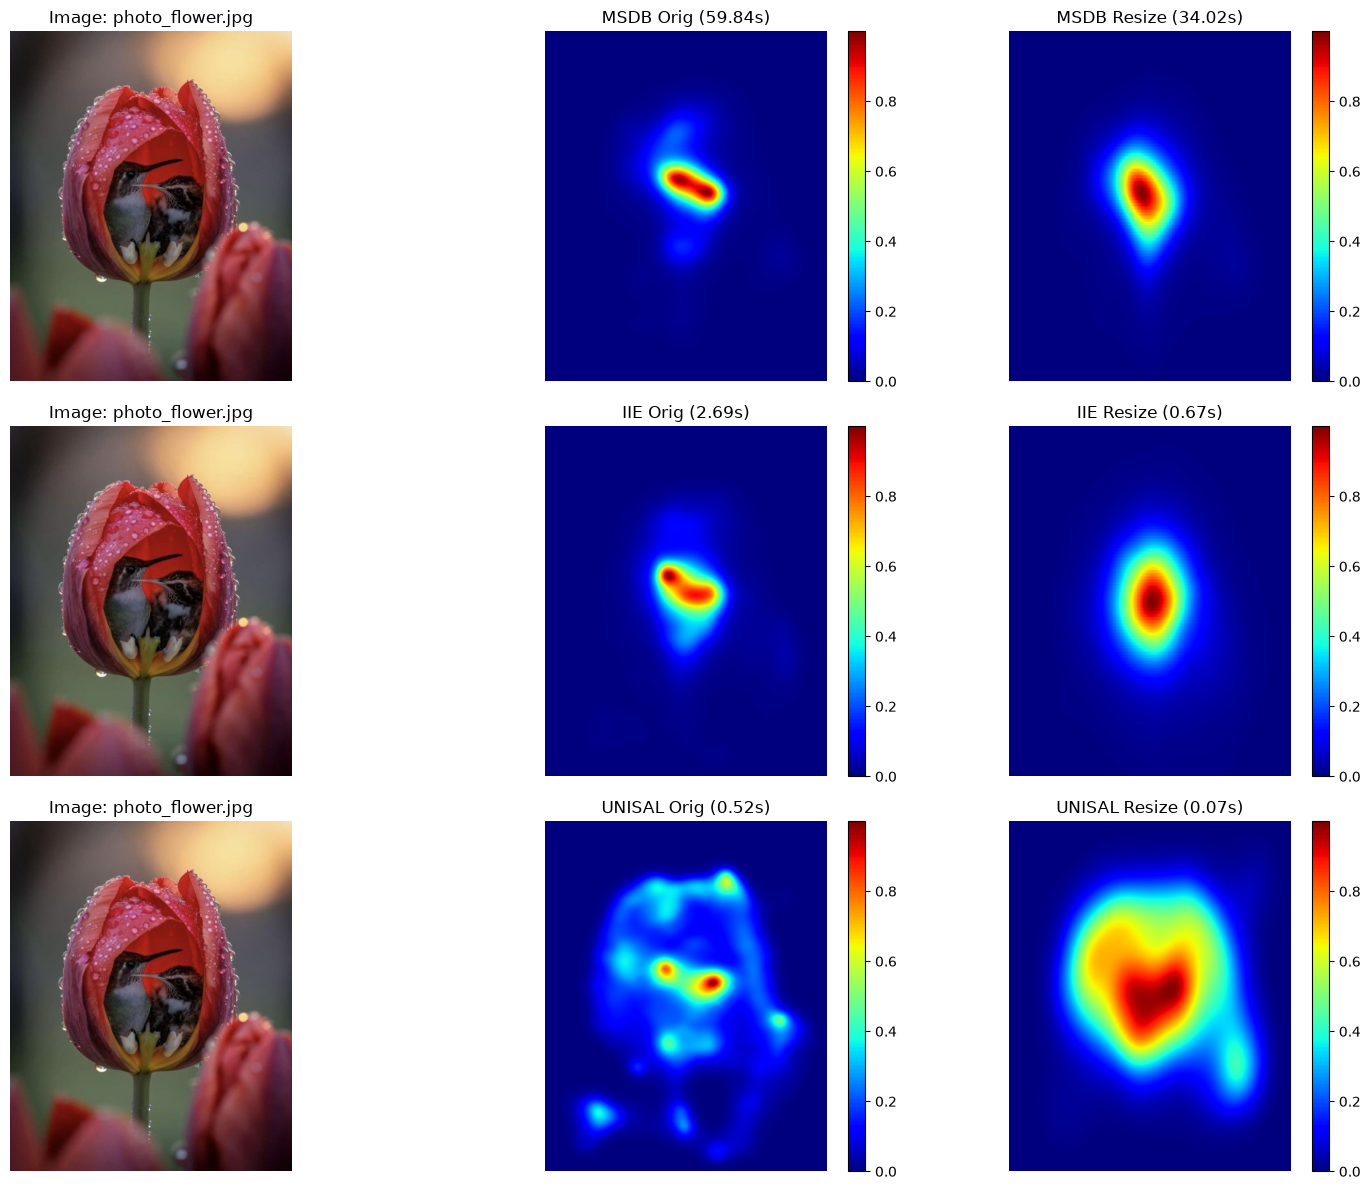

photo_woman.jpg (736x1098)
DeepGaze MSDB orig: 58.982s, resize: 34.286s
DeepGaze IIE orig: 3.431s, resize: 0.655s
UNISAL orig: 0.662s, resize: 0.081s



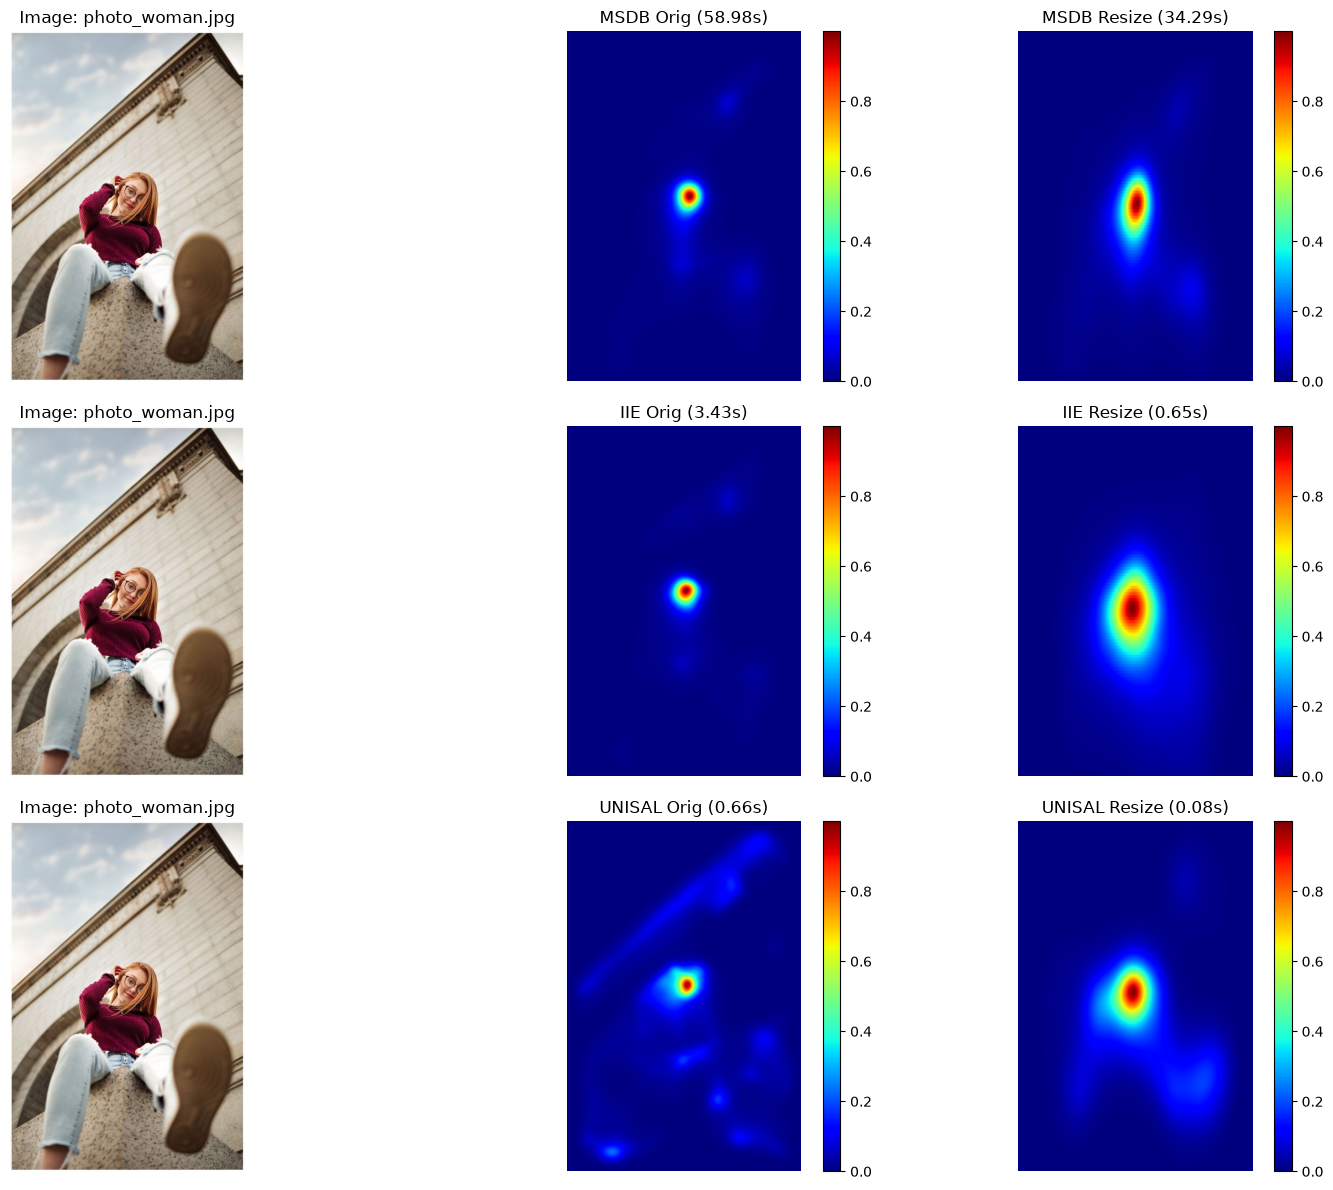

Rosenblatt.jpg (387x429)
DeepGaze MSDB orig: 46.284s, resize: 26.207s
DeepGaze IIE orig: 0.949s, resize: 0.626s
UNISAL orig: 0.111s, resize: 0.064s



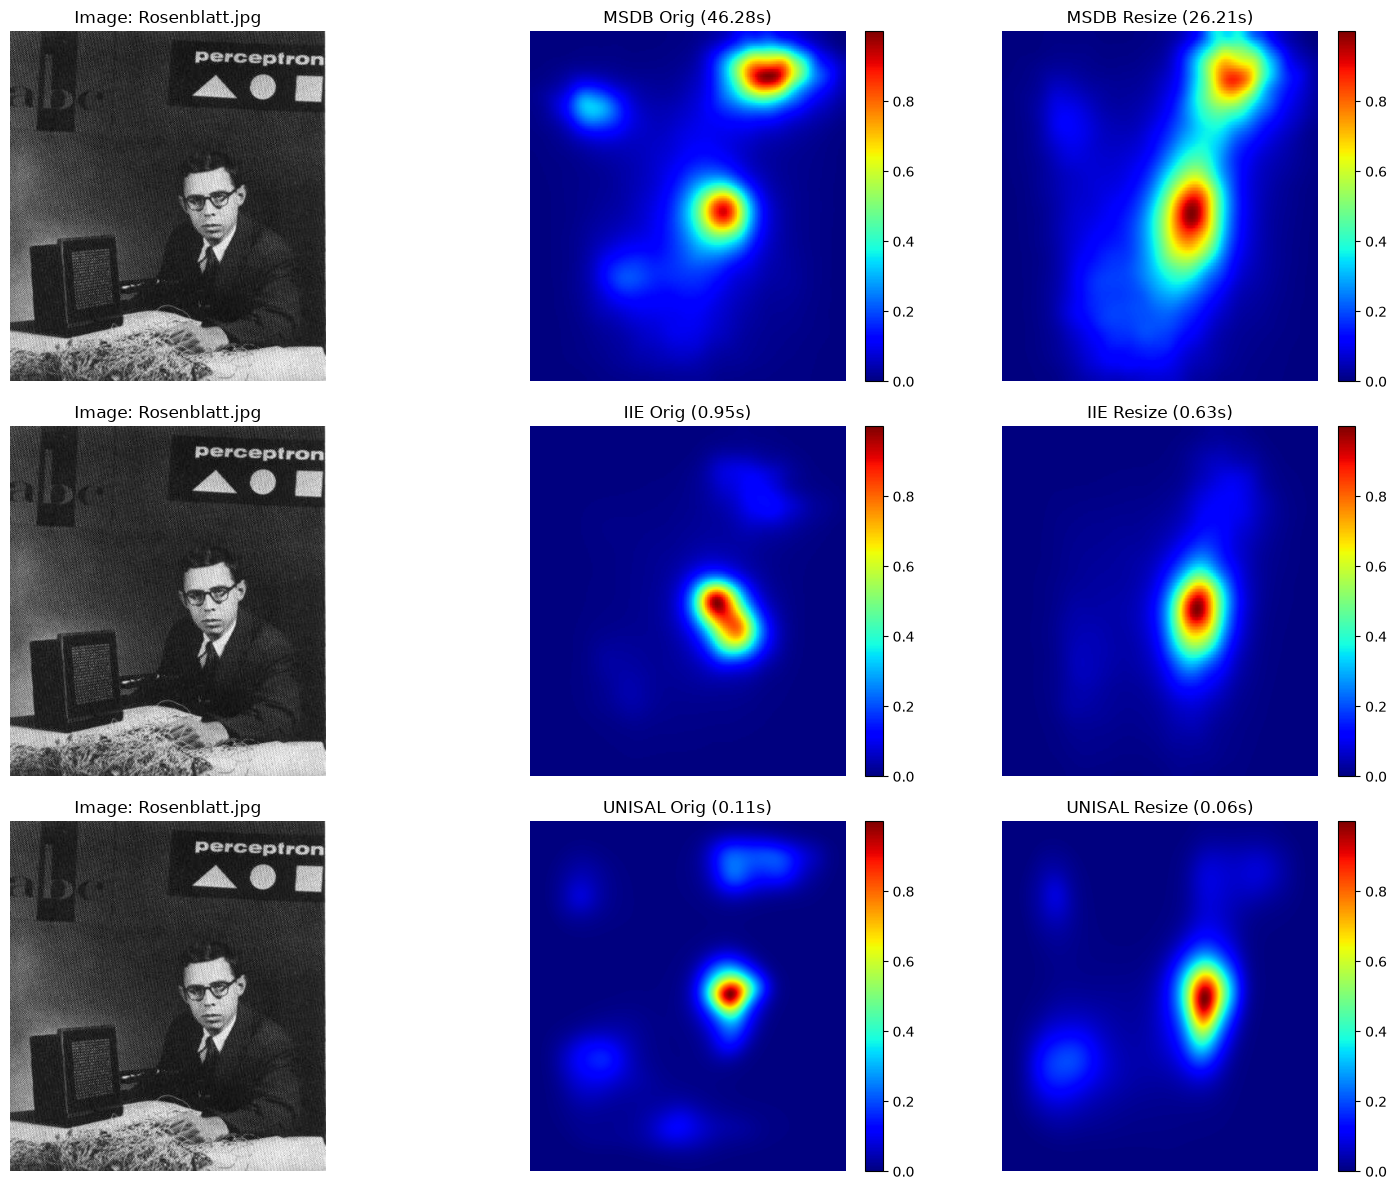

tiger.jpg (736x1104)
DeepGaze MSDB orig: 59.711s, resize: 33.949s
DeepGaze IIE orig: 3.301s, resize: 0.596s
UNISAL orig: 0.574s, resize: 0.059s



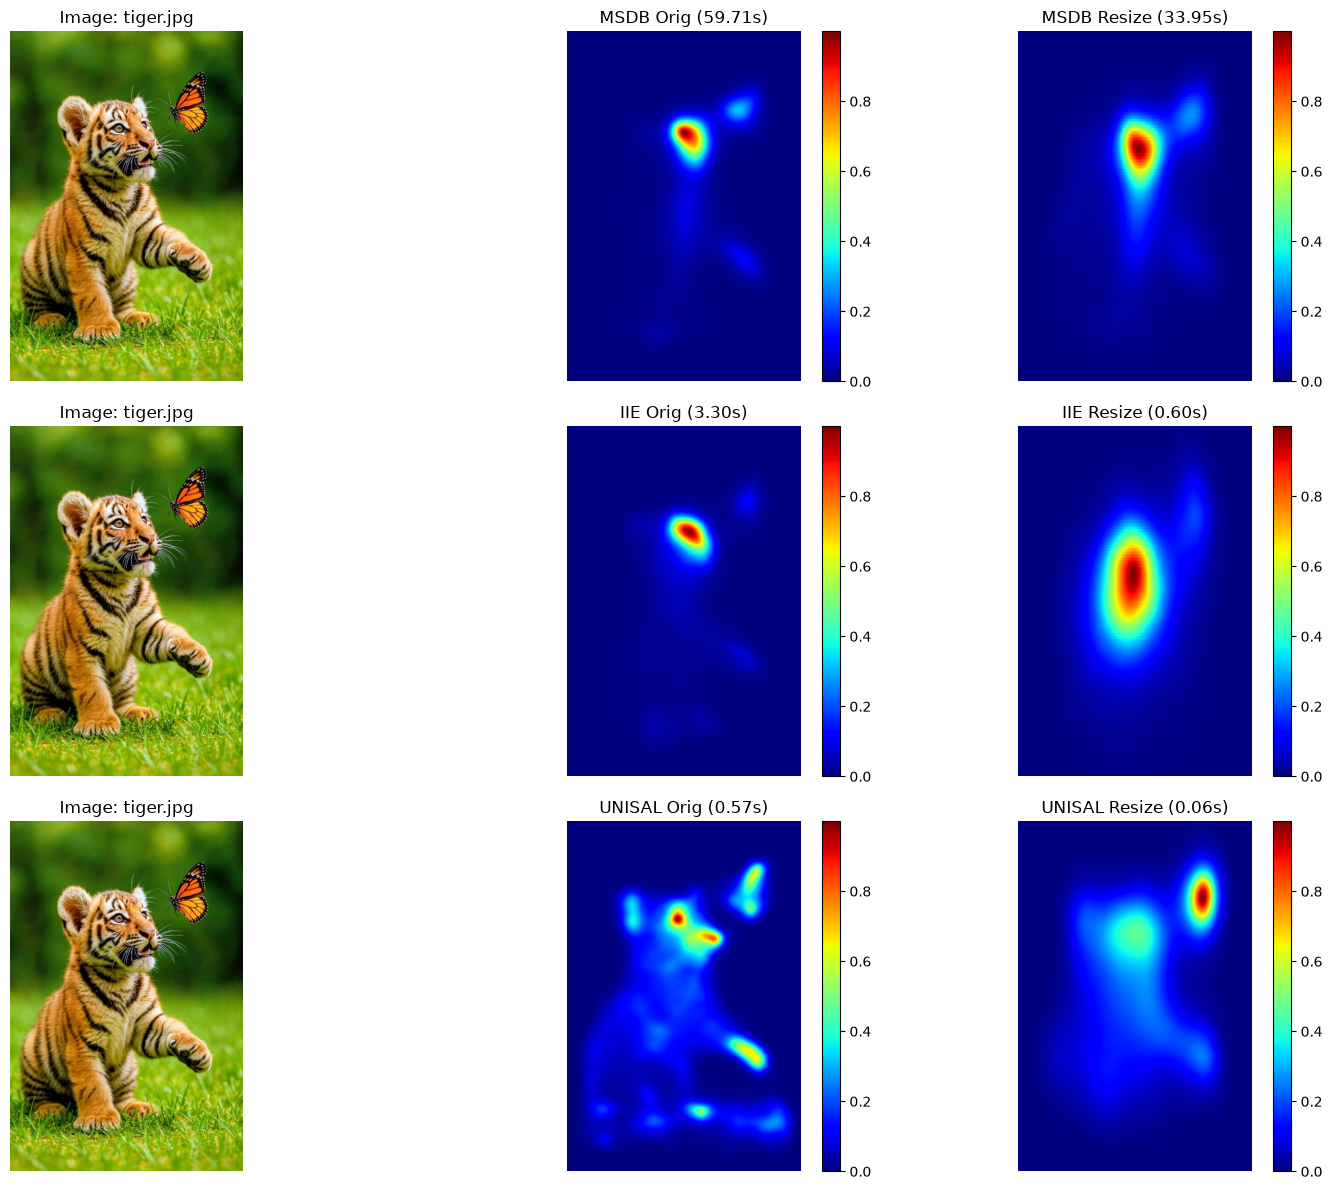

In [12]:
unisal_norm = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

ex_dir = Path('./examples')
image_paths = sorted(p for p in ex_dir.iterdir() if p.is_file() and p.suffix.lower() in ('.png', '.jpg'))

small_h, small_w = 224, 384

for image_path in image_paths:
    image_pil = Image.open(image_path).convert('RGB')
    image = np.array(image_pil)
    orig_h, orig_w = image.shape[:2]

    image_small_pil = image_pil.resize((small_w, small_h), Image.BILINEAR)
    image_small = np.array(image_small_pil)

    cb_orig = prepare_centerbias((orig_h, orig_w), centerbias_template)
    cb_small = prepare_centerbias((small_h, small_w), centerbias_template)

    tensor_msdb_orig = torch.from_numpy(image).permute(2, 0, 1).unsqueeze(0).float().to(DEVICE)
    t0 = time.perf_counter()
    with torch.no_grad():
        pred_msdb_orig = model_msdb(tensor_msdb_orig, cb_orig, pixel_per_dva=35.0, dataset=None)
    t_inf_msdb_orig = time.perf_counter() - t0
    dens_msdb_orig = np.exp(pred_msdb_orig.squeeze().cpu().numpy())
    dens_msdb_orig = (dens_msdb_orig - dens_msdb_orig.min()) / (dens_msdb_orig.max() - dens_msdb_orig.min() + 1e-8)

    tensor_msdb_small = torch.from_numpy(image_small).permute(2, 0, 1).unsqueeze(0).float().to(DEVICE)
    t0 = time.perf_counter()
    with torch.no_grad():
        pred_msdb_small = model_msdb(tensor_msdb_small, cb_small, pixel_per_dva=35.0 * (small_w / orig_w), dataset=None)
    t_inf_msdb_small = time.perf_counter() - t0
    dens_msdb_small = np.exp(pred_msdb_small.squeeze().cpu().numpy())
    dens_msdb_small = zoom(dens_msdb_small, (orig_h / small_h, orig_w / small_w), order=1)
    dens_msdb_small = (dens_msdb_small - dens_msdb_small.min()) / (dens_msdb_small.max() - dens_msdb_small.min() + 1e-8)

    tensor_iie_orig = torch.from_numpy(image).permute(2, 0, 1).unsqueeze(0).float().to(DEVICE)
    t0 = time.perf_counter()
    with torch.no_grad():
        pred_iie_orig = model_iie(tensor_iie_orig, cb_orig)
    t_inf_iie_orig = time.perf_counter() - t0
    dens_iie_orig = np.exp(pred_iie_orig.squeeze().cpu().numpy())
    dens_iie_orig = (dens_iie_orig - dens_iie_orig.min()) / (dens_iie_orig.max() - dens_iie_orig.min() + 1e-8)

    tensor_iie_small = torch.from_numpy(image_small).permute(2, 0, 1).unsqueeze(0).float().to(DEVICE)
    t0 = time.perf_counter()
    with torch.no_grad():
        pred_iie_small = model_iie(tensor_iie_small, cb_small)
    t_inf_iie_small = time.perf_counter() - t0
    dens_iie_small = np.exp(pred_iie_small.squeeze().cpu().numpy())
    dens_iie_small = zoom(dens_iie_small, (orig_h / small_h, orig_w / small_w), order=1)
    dens_iie_small = (dens_iie_small - dens_iie_small.min()) / (dens_iie_small.max() - dens_iie_small.min() + 1e-8)

    full_h = (orig_h // 32) * 32
    full_w = (orig_w // 32) * 32
    img_unisal_full_pil = image_pil.resize((full_w, full_h), Image.BILINEAR)
    tensor_unisal_orig = unisal_norm(T.ToTensor()(img_unisal_full_pil)).unsqueeze(0).unsqueeze(0).to(DEVICE)
    t0 = time.perf_counter()
    with torch.no_grad():
        pred_unisal_orig = model_unisal(tensor_unisal_orig, source='SALICON')
    t_inf_unisal_orig = time.perf_counter() - t0
    dens_unisal_orig = np.exp(pred_unisal_orig.squeeze().cpu().numpy())
    dens_unisal_orig = zoom(dens_unisal_orig, (orig_h / dens_unisal_orig.shape[0], orig_w / dens_unisal_orig.shape[1]), order=1)
    dens_unisal_orig = (dens_unisal_orig - dens_unisal_orig.min()) / (dens_unisal_orig.max() - dens_unisal_orig.min() + 1e-8)

    tensor_unisal_small = unisal_norm(T.ToTensor()(image_small_pil)).unsqueeze(0).unsqueeze(0).to(DEVICE)
    t0 = time.perf_counter()
    with torch.no_grad():
        pred_unisal_small = model_unisal(tensor_unisal_small, source='SALICON')
    t_inf_unisal_small = time.perf_counter() - t0
    dens_unisal_small = np.exp(pred_unisal_small.squeeze().cpu().numpy())
    dens_unisal_small = zoom(dens_unisal_small, (orig_h / dens_unisal_small.shape[0], orig_w / dens_unisal_small.shape[1]), order=1)
    dens_unisal_small = (dens_unisal_small - dens_unisal_small.min()) / (dens_unisal_small.max() - dens_unisal_small.min() + 1e-8)

    print(f"{image_path.name} ({orig_w}x{orig_h})")
    print(f"DeepGaze MSDB orig: {t_inf_msdb_orig:.3f}s, resize: {t_inf_msdb_small:.3f}s")
    print(f"DeepGaze IIE orig: {t_inf_iie_orig:.3f}s, resize: {t_inf_iie_small:.3f}s")
    print(f"UNISAL orig: {t_inf_unisal_orig:.3f}s, resize: {t_inf_unisal_small:.3f}s")
    print()

    fig, axes = plt.subplots(3, 3, figsize=(15, 12))

    axes[0, 0].imshow(image)
    axes[0, 0].set_title(f"Image: {image_path.name}")
    axes[0, 0].axis('off')
    h = axes[0, 1].imshow(dens_msdb_orig, cmap='jet')
    axes[0, 1].set_title(f"MSDB Orig ({t_inf_msdb_orig:.2f}s)")
    axes[0, 1].axis('off')
    plt.colorbar(h, ax=axes[0, 1], fraction=0.046, pad=0.04)
    h = axes[0, 2].imshow(dens_msdb_small, cmap='jet')
    axes[0, 2].set_title(f"MSDB Resize ({t_inf_msdb_small:.2f}s)")
    axes[0, 2].axis('off')
    plt.colorbar(h, ax=axes[0, 2], fraction=0.046, pad=0.04)

    axes[1, 0].imshow(image)
    axes[1, 0].set_title(f"Image: {image_path.name}")
    axes[1, 0].axis('off')
    h = axes[1, 1].imshow(dens_iie_orig, cmap='jet')
    axes[1, 1].set_title(f"IIE Orig ({t_inf_iie_orig:.2f}s)")
    axes[1, 1].axis('off')
    plt.colorbar(h, ax=axes[1, 1], fraction=0.046, pad=0.04)
    h = axes[1, 2].imshow(dens_iie_small, cmap='jet')
    axes[1, 2].set_title(f"IIE Resize ({t_inf_iie_small:.2f}s)")
    axes[1, 2].axis('off')
    plt.colorbar(h, ax=axes[1, 2], fraction=0.046, pad=0.04)

    axes[2, 0].imshow(image)
    axes[2, 0].set_title(f"Image: {image_path.name}")
    axes[2, 0].axis('off')
    h = axes[2, 1].imshow(dens_unisal_orig, cmap='jet')
    axes[2, 1].set_title(f"UNISAL Orig ({t_inf_unisal_orig:.2f}s)")
    axes[2, 1].axis('off')
    plt.colorbar(h, ax=axes[2, 1], fraction=0.046, pad=0.04)
    h = axes[2, 2].imshow(dens_unisal_small, cmap='jet')
    axes[2, 2].set_title(f"UNISAL Resize ({t_inf_unisal_small:.2f}s)")
    axes[2, 2].axis('off')
    plt.colorbar(h, ax=axes[2, 2], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()